# Dominant ionic currents in rabbit ventricular action potential dynamics

__Zhechao Yang__, School of Mathematics and Statistics, University of Glasgow, Glasgow, United Kingdom

__Hao Gao__, School of Mathematics and Statistics, University of Glasgow, Glasgow, United Kingdom

__Godfrey L. Smith__, School of Cardiovascular and Metabolic Health, University of Glasgow, Glasgow, United Kingdom

__Radostin D. Simitev__, School of Mathematics and Statistics, University of Glasgow, Glasgow, United Kingdom

Notebook: Claude (Anthropic) for P. Constantine, 2026

This notebook runs in Python 3 with numpy, scipy, matplotlib and [active_subspaces](https://github.com/paulcon/active_subspaces) version 1.0 or later, and takes under two minutes. It reads stored data: the model runs need Myokit and took 52 minutes of CPU (see `DATA.md`).

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import active_subspaces as ac
import shannon_driver as sm
import generate_data as gd

SEED = 328261                     # the only seed in this notebook (bootstrap)
t_start = time.perf_counter()
labels = [r'$p_{\rm NaK}$', r'$p_{\rm K1}$', r'$p_{\rm CaL}$', r'$p_{\rm Cap}$', r'$p_{\rm Na}$',
          r'$p_{\rm Kr}$', r'$p_{\rm NaCa}$', r'$p_{\rm Ks}$', r'$p_{\rm ClCa}$', r'$p_{\rm Nab}$',
          r'$p_{\rm tos}$', r'$p_{\rm Clb}$', r'$p_{\rm Cab}$', r'$p_{\rm Kp}$', r'$p_{\rm tof}$']
NAMES = sm.NAMES
QOIS = gd.QOIS                    # Vmax, Vrest, A90, A30, Vplt, B, Cai_ED, Cai_PSV
UNITS = dict(zip(QOIS, gd.QUNITS))

### Summary

Yang et al. [[1]](https://doi.org/10.1371/journal.pone.0328261) scale the 15 ionic currents of the Shannon et al. (2004) rabbit ventricular myocyte model [[2]](https://doi.org/10.1529/biophysj.104.047449) (in their model file, with the subsarcolemmal Na reversal potential fixed at −15 mV) by factors $p_i$, pace the cell for 1000 beats, and rank the factors by Sobol' indices of six action potential (AP) biomarkers; we ran the same model and protocol at 320 scrambled Sobol' points in their parameter box (Table 4), of which 288 give a normal 1:1 response, and estimate active subspaces from the values with the global quadratic (QPHD) estimator. Every biomarker has one dominant direction, with moderate gaps ($\lambda_1/\lambda_2$ = 5.6 for the AP duration $A_{90}$ and 16.3 for the resting potential), and a quadratic in two active variables has leave-one-out $R^2$ between 0.875 and 0.922 for five of the six AP biomarkers. The most important input here is the Na-K pump factor $p_{\rm NaK}$, which the paper ranks seventh, and our runs do not reproduce the biomarker distributions of the 2000 full-model runs stored in the authors' repository (median $A_{90}$ 88.6 ms here against 144.2 ms there, peak potential 15.0 against 21.0 mV); the cause is not known. The paper states the same model file and 1000-beat protocol, but its one-at-a-time Fig 2(a) is matched only by the first 5–20 beats of this file: varying $p_{\rm NaK}$ alone, a weak pump gives long APs early in the train and the shortest ones at beat 1000, after Na loading. At beat 500, where the cells are less Na-loaded, $A_{90}$ is led by $p_{\rm Clb}$, $p_{\rm K1}$ and $p_{\rm Kr}$, close to the paper's ordering.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend and a function of $\mathbf y$ can stand in for $f$. Here there are no gradients, so $\mathbf C$ is estimated from a least-squares quadratic fit to the values; the bootstrap measures how well the eigenvalues and subspaces are determined. See P. G. Constantine [[3]](https://doi.org/10.1137/1.9781611973860), *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015.

### The model

The Shannon et al. model [[2]](https://doi.org/10.1529/biophysj.104.047449) describes a rabbit ventricular myocyte with junctional, subsarcolemmal and bulk cytosolic Ca compartments, SR release and uptake, Ca and Na buffering and 15 transmembrane currents (39 ODE states in the Myokit file). Yang et al. [[1]](https://doi.org/10.1371/journal.pone.0328261) (Eq 1, p. 5) multiply each current by a factor $p_i$ wherever it appears:

$$
\frac{dV}{dt} = -\Big(\sum_{i=1}^{15} p_i\, I_i(V, \mathbf z, \mathbf c) + I_{\rm stim}(t)\Big),
$$

where $\mathbf z$ are gating variables and $\mathbf c$ concentrations (whose equations contain the same scaled currents). The model file is the authors' (`shannon_wang_puglisi_weber_bers_2004_a_p.mmt`, from their repository): **Shannon et al. 2004 with the subsarcolemmal Na reversal potential $E_{\rm Na,SL}$ fixed at −15 mV, as distributed by Yang et al.** The published model computes it by the Nernst equation from $[{\rm Na}]_o$ and the subsarcolemmal $[{\rm Na}]_{\rm SL}$ (Shannon et al., Eq 10, p. 3363), and 89 % of the Na channels sit in that compartment (p. 3364); the file keeps the Nernst line as a comment. The file also multiplies $R$, $T$, $F$, $[{\rm Cl}]_i$ and $[{\rm Cl}]_o$ by constants p1–p5 (all 1, so they change nothing) and starts the stimulus at 76 ms instead of the 20 ms of the original protocol line, which it keeps as a comment. The paper does not mention these edits (it says the factors "allow the original model formulation to be used without modification", p. 5), but its Fig 2(d) baseline AP peaks near 26 mV, as this file does, so the paper's runs used it too. $p_i = 1$ is therefore this file unscaled, not the published model: at that point the fixed $E_{\rm Na,SL}$ lowers the peak potential of beat 1000 from about 43 to 26 mV (`check_accuracy.py`, check 3; `DATA.md`). We keep the file, because it is what the paper ran. The stimulus is 9.5 A/F with basic cycle length $t_{\rm BCL} = 500$ ms (paper p. 10); its 5 ms duration and its start at $t_0 = 76$ ms of each beat come from the model file. The paper notes that the excitation threshold at baseline is about 9.4 A/F (p. 11). Each run starts from the initial state in the model file, paces 1000 beats (p. 10) with Myokit and CVODES, and records the biomarkers of the last beat (Table 3, p. 6). At the nominal point the stimulus is so close to threshold that an occasional beat fails, and which one depends on how the integration is split; in the box ($p_{\rm Na} \ge 1$) the cell is more excitable, and reruns with two other splits reproduced $A_{90}$ to within 0.03 % for 9 of the 10 rows checked and 1.9 % for the tenth (`DATA.md`). The biomarkers:

- $V_{\max}$, peak potential; $V_{\rm rest} = V(t_{\rm BCL})$, potential at the end of the beat;
- $A_{90}$, $A_{30}$: time from the stimulus to the first crossing of $V_{\max} - 0.9\,(V_{\max} - V_{\rm rest})$ (or $0.3$) after the peak;
- $V_{\rm plt} = V(t_0 + A_{90}/2)$, plateau potential; $B = \int_0^{t_{\rm BCL}} |V - V_{\rm rest}|\,dt$, the AP "bulk";
- two Ca biomarkers that the paper also uses (pp. 18–19): end-diastolic and peak cytosolic $[{\rm Ca}^{2+}]_i$ (`Cai_ED`, `Cai_PSV`).

The inputs are the 15 factors, independent and uniform on the ranges of the paper's Table 4 (p. 12), the box in which each factor alone, with the others at 1, keeps a normal 1:1 response. The paper samples them uniformly on a linear scale (SALib Saltelli), and so do we: a lower bound of $10^{-4}$ stands for a blocked current, and a log scale would put most of the samples where the current is negligible. The table below is printed from `shannon_driver.py`.

This model differs from the three other cardiac and neural cell models in this repository: `Hodgkin_Huxley_Action_Potential` (squid giant axon, 4 states), `Luo_Rudy_Cardiac_Action_Potential` (Luo-Rudy 1991 guinea-pig ventricular cell, a single AP) and `Atrial_Cell_Models_Courtemanche_Maleckar` (human atrial cells). Here the cell is rabbit ventricular, with detailed subsarcolemmal Ca handling, and the outputs are those of the 1000th paced beat, so slow ion accumulation over minutes of pacing enters the biomarkers.

In [2]:
desc = {'pNaK': 'Na-K pump', 'pK1': 'inward rectifier K', 'pCaL': 'L-type Ca', 'pCap': 'sarcolemmal Ca pump',
        'pNa': 'fast Na', 'pKr': 'fast delayed rectifier K', 'pNaCa': 'Na/Ca exchanger',
        'pKs': 'slow delayed rectifier K', 'pClCa': 'Ca-activated Cl', 'pNab': 'background Na',
        'ptos': 'slow transient outward K', 'pClb': 'background Cl', 'pCab': 'background Ca',
        'pKp': 'plateau K', 'ptof': 'fast transient outward K'}
print(f"{'input':6s} {'Myokit constant':16s} {'lower':>7s} {'upper':>6s} {'nominal':>7s}  scales the current")
for (n, var, lo, hi) in sm.INPUTS:
    print(f'{n:6s} {var:16s} {lo:7.4g} {hi:6.4g} {1:7d}  {desc[n]}')
print(f'\nprotocol: BCL {sm.BCL:g} ms, stimulus at t0 = {sm.T0:g} ms of each beat (5 ms, 9.5 A/F), '
      f'{gd.N_BEATS} beats, logging step {sm.DT_LOG} ms')

input  Myokit constant    lower  upper nominal  scales the current
pNaK   INaK.p            0.0001   1.07       1  Na-K pump
pK1    IK1.p               0.03   1.01       1  inward rectifier K
pCaL   ICaL.p               0.7    1.6       1  L-type Ca
pCap   ICap.p            0.0001    4.5       1  sarcolemmal Ca pump
pNa    INa.p                  1     10       1  fast Na
pKr    IKr.p             0.0001    3.2       1  fast delayed rectifier K
pNaCa  INaCa.p              0.6      3       1  Na/Ca exchanger
pKs    IKs.p             0.0001     10       1  slow delayed rectifier K
pClCa  ICl_Ca.p          0.0001     10       1  Ca-activated Cl
pNab   INab.p            0.0001     10       1  background Na
ptos   Itos.p            0.0001    2.5       1  slow transient outward K
pClb   IClb.p            0.0001     10       1  background Cl
pCab   ICab.p              0.34     10       1  background Ca
pKp    IKp.p             0.0001     10       1  plateau K
ptof   Itof.p            0.0001    

### Load data

`generate_data.py` ran the model at the first 320 points of one scrambled Sobol' sequence (scipy, seed 20251031) in the Table 4 box and wrote `rabbit_ap_samples.csv`: the 15 physical factors, the 8 biomarkers of beat 1000, $A_{90}$ of beat 999, the 8 biomarkers of beat 500 (a convergence check), a response code and the CPU time of each run (see `DATA.md`). Every run is in the file.

In [3]:
D = np.loadtxt('rabbit_ap_samples.csv', delimiter=',')
col = {c: j for j, c in enumerate(gd.COLS)}
resp = D[:, col['response']].astype(int)
print(f'{D.shape[0]} rows x {D.shape[1]} columns: 15 inputs, 8 biomarkers (beat {gd.N_BEATS}), '
      f'A90 of beat {gd.N_BEATS - 1}, 8 biomarkers (beat {gd.CHECK_BEAT}), response, cpu_s')
print('responses:', ', '.join(f'{c} {int(np.sum(resp == v))}' for c, v in gd.CLASSES.items()))

320 rows x 34 columns: 15 inputs, 8 biomarkers (beat 1000), A90 of beat 999, 8 biomarkers (beat 500), response, cpu_s
responses: normal 288, no_AP 16, alternans_or_2to1 16


The next cell is the one place where rows are selected. The rule: keep the rows with response 0, a normal 1:1 AP train in the last two beats. Response 1 (no AP: $V_{\max} \le 0$ mV in beat 999 or 1000) and response 2 (alternans or 2:1: $A_{90}$ of the last two beats differs by more than 2 %) are outside the paper's region of normal response, which Table 4 found one factor at a time; joint corners of the box can leave it. The rule reads only the last two beats, so it can miss an intermittent response (p. 11 and Fig 2(e): about 20 normal APs, then an equally long phase without APs) whenever beats 999 and 1000 fall in an AP phase; one kept row has a failed beat 500 ($V_{\max} < 0$ at beat 500, printed below). The exclusion also thins the design where the pump is weak: the cell prints how many rows it drops in each fifth of the $p_{\rm NaK}$ range, and the kept $p_{\rm NaK}$ values are no longer quite uniform. QPHD averages $\nabla q\,\nabla q^T$ over the whole box, so it extrapolates the quadratic into the dropped region, mostly where $p_{\rm NaK}$ acts; the checks after the estimate repeat it on all 320 rows. The rule also admits some pathological cells, which we flag but keep (the rule stays as stated; check (e) below repeats the estimate without them): rows with end-diastolic $[{\rm Ca}^{2+}]_i$ above 1 µM (`Cai_ED` > 1e-3 mM; Ca overload, against a median near 0.1 µM) and rows whose peak potential is below 5 mV (a small AP, like the no-AP rows just below 0 mV). The flags are computed here from the stored biomarkers; the CSV is unchanged. The cell lists the excluded rows, the flagged rows, the cost of the runs, and how much the biomarkers changed between beats 500 and 1000. The analysis works in normalized coordinates $x_i \in [-1, 1]$; `ac.Uniform` maps the physical factors once.

In [4]:
assert np.allclose(D[:, :15], gd.design(), rtol=1e-11, atol=0)   # the rows are the Sobol' design
keep = resp == 0                                   # the rule: normal 1:1 response only
X = D[keep, :15]                                   # physical scaling factors
F = {q: D[keep, col[q]] for q in QOIS}             # biomarkers of the last beat
F500 = {q: D[keep, col['b500_' + q]] for q in QOIS}
M = len(X)
space = ac.Uniform(sm.LOWER, sm.UPPER, names=NAMES)   # linear scale, as sampled
XN = space.to_normalized(X)                        # x in [-1, 1]^15, used only for printing
for j in np.flatnonzero(~keep):
    big = [f'{NAMES[i]} {D[j, i]:.3g}' for i in np.argsort(-(D[j, :15] - sm.LOWER) / (sm.UPPER - sm.LOWER))[:3]]
    print(f'row {j}: response {resp[j]}, Vmax {D[j, col["Vmax"]]:.1f} mV, A90 {D[j, col["A90"]]:.1f} / '
          f'{D[j, col["A90_prev"]]:.1f} ms (last two beats); largest scaled inputs {", ".join(big)}')
print(f'M = {M} normal rows used; (m+1)(m+2)/2 = {16 * 17 // 2}')
from scipy import stats
qe = np.quantile(D[:, 0], [0.2, 0.4, 0.6, 0.8])
quint = np.digitize(D[:, 0], qe)
print(f'excluded rows by pNaK quintile of the design (edges {np.array2string(qe, precision=3)}): '
      + ', '.join(f'{int(np.sum(~keep & (quint == k)))} of {int(np.sum(quint == k))}' for k in range(5)))
kurt = stats.kurtosis(XN, axis=0, fisher=False)
print(f'kept rows: kurtosis of normalized pNaK {kurt[0]:.2f} (uniform: 1.80; other inputs {kurt[1:].min():.2f} to '
      f'{kurt[1:].max():.2f}); KS test of the kept pNaK against uniform: p = '
      f'{stats.kstest((XN[:, 0] + 1) / 2, "uniform").pvalue:.3f}')
print(f'normal rows whose beat 500 has Vmax < 0 mV: {int(np.sum(F500["Vmax"] < 0))}')
cao = F['Cai_ED'] > 1e-3                           # flag: end-diastolic [Ca]i above 1 uM (Ca overload)
small = F['Vmax'] < 5.0                            # flag: peak potential below 5 mV (small AP)
flag = cao | small
print(f'flagged normal rows (kept): Ca overload {cao.sum()} (Cai_ED up to {F["Cai_ED"][cao].max() * 1e3:.1f} uM; '
      f'median of the normal rows {np.median(F["Cai_ED"]) * 1e3:.3f} uM); Vmax < 5 mV {small.sum()} '
      f'(Vmax from {F["Vmax"][small].min():.2f} mV, A90 {F["A90"][small].min():.0f} to {F["A90"][small].max():.0f} ms); '
      f'both {int(np.sum(cao & small))}, either {flag.sum()}; largest pNaK among them {X[flag, 0].max():.2f}')
cpu = D[:, col['cpu_s']]
print(f'cost: {cpu.mean():.1f} s CPU per run (min {cpu.min():.1f}, max {cpu.max():.1f}), '
      f'total {cpu.sum() / 3600:.2f} h CPU for {len(D)} runs')

print(f"\nbeat {gd.CHECK_BEAT} vs beat {gd.N_BEATS}: change d = q(1000) - q(500), normal rows")
print(f"{'QoI':8s} {'units':6s} {'median |d|':>11s} {'90% |d|':>9s} {'max |d|':>9s} {'sd of q':>9s} "
      f"{'median|d|/sd':>12s} {'corr(q500,q1000)':>16s}")
conv = {}
for q in QOIS:
    d = F[q] - F500[q]
    sd = F[q].std()
    conv[q] = (np.median(np.abs(d)) / sd, np.corrcoef(F500[q], F[q])[0, 1])
    print(f'{q:8s} {UNITS[q]:6s} {np.median(np.abs(d)):11.4g} {np.percentile(np.abs(d), 90):9.4g} '
          f'{np.abs(d).max():9.4g} {sd:9.4g} {conv[q][0]:12.3f} {conv[q][1]:16.4f}')
rA = np.abs(F['A90'] - F500['A90']) / F['A90']
print(f'A90: relative change beat 500 -> 1000: median {np.median(rA):.1%}, '
      f'{np.mean(rA > 0.02):.0%} of rows above 2 %, max {rA.max():.1%}')

row 10: response 2, Vmax 3.2 mV, A90 51.8 / 53.0 ms (last two beats); largest scaled inputs ptof 3.89, pNa 9.6, pNaCa 2.83
row 26: response 1, Vmax -1.3 mV, A90 42.9 / 36.1 ms (last two beats); largest scaled inputs pClb 9.65, pKp 8.95, pClCa 7.69
row 29: response 2, Vmax 1.2 mV, A90 63.3 / 52.4 ms (last two beats); largest scaled inputs pClb 8.73, pNab 8.51, pCab 8.5
row 37: response 1, Vmax -12.7 mV, A90 39.9 / 40.0 ms (last two beats); largest scaled inputs ptof 3.85, pNaCa 2.91, pCab 9.57
row 50: response 1, Vmax -3.2 mV, A90 42.3 / 39.5 ms (last two beats); largest scaled inputs pCab 9.83, pKs 9.5, pCap 4.24
row 54: response 2, Vmax 5.4 mV, A90 391.6 / 26.6 ms (last two beats); largest scaled inputs pCaL 1.58, ptof 3.67, pNab 7.63
row 74: response 1, Vmax -0.5 mV, A90 47.1 / 47.1 ms (last two beats); largest scaled inputs pK1 0.885, pKp 7.95, pClb 7.42
row 77: response 1, Vmax -12.8 mV, A90 50.2 / 56.6 ms (last two beats); largest scaled inputs pNab 9.75, pKs 8.89, pNaCa 2.73
row 

### Estimate the subspace

There are no gradients (a finite difference through a 1000-beat train is costly and noisy), so we use the global quadratic estimator `estimator="qphd"`: fit $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$ by least squares in normalized coordinates and take $\hat{\mathbf C} = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$, the average of $\nabla q\,\nabla q^T$ over the input density ($\boldsymbol\Sigma = \tfrac13\mathbf I$ for the uniform box). The fit has $(m+1)(m+2)/2 = 136$ coefficients and we have $M = 288$ rows, more than twice that. v1 warns that the method's theory (Stein's lemma) assumes Gaussian inputs; on a uniform box the formula is still the exact average of $\nabla q\,\nabla q^T$, so the estimate is as good as the quadratic fit, whose leave-one-out $R^2$ the next cell prints. The bootstrap uses 500 resamples of the rows with `rng=SEED`. Each subspace is oriented so that the biomarker increases along $\mathbf w_1$.

In [5]:
def quad_features(Z):
    """Monomials 1, z_j, z_j z_k (j <= k) of normalized inputs."""
    m = Z.shape[1]
    cols = [np.ones(len(Z))] + [Z[:, j] for j in range(m)]
    cols += [Z[:, j] * Z[:, k] for j in range(m) for k in range(j, m)]
    return np.column_stack(cols)


Q = quad_features(XN)


def quad_loo_r2(f):
    """Leave-one-out R^2 of the least-squares quadratic in all 15 inputs (hat-matrix formula)."""
    H = Q @ np.linalg.pinv(Q)
    e = (f - H @ f) / (1 - np.diag(H))
    return 1 - np.sum(e**2) / np.sum((f - f.mean())**2)


def estimate(q, nboot=500):
    sub = ac.active_subspace(space=space, X=X, f=F[q], estimator='qphd', nboot=nboot, rng=SEED, qoi=q)
    return ac.orient(sub, by='covariance', X=X, f=F[q], columns=2)


def top(w, k=3):
    return ', '.join(f'{NAMES[j]} {w[j]:+.2f}' for j in np.argsort(-np.abs(w))[:k])


import warnings
subs, loo = {}, {}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    for q in QOIS:
        subs[q] = estimate(q)
        loo[q] = quad_loo_r2(F[q])
print('warnings from v1:', sorted({type(w.message).__name__ + ': ' + str(w.message)[:110] for w in caught}))
print(f"\n{'QoI':8s} {'quad LOO R2':>11s} {'l1/l2':>7s} {'l2/l3':>6s} {'l3/l4':>6s} {'n (evg)':>7s}  w1: top 3")
for q in QOIS:
    lam = subs[q].eigenvalues
    print(f'{q:8s} {loo[q]:11.3f} {lam[0] / lam[1]:7.1f} {lam[1] / lam[2]:6.1f} {lam[2] / lam[3]:6.1f} '
          f'{subs[q].n:7d}  {top(subs[q].W[:, 0])}')

warnings from v1: ["ValidityWarning: outside the method's assumptions; estimator 'qphd' on a uniform space: the least-squares quadratic gives E[gra"]

QoI      quad LOO R2   l1/l2  l2/l3  l3/l4 n (evg)  w1: top 3
Vmax           0.882     5.7    1.7    4.7       1  pNaK +0.81, pClb -0.34, pK1 -0.23
Vrest          0.865    16.3    1.6    3.0       1  pK1 -0.87, pClb +0.38, pCab +0.21
A90            0.805     5.6    2.9    1.5       1  pNaK +0.62, pClb -0.49, pK1 -0.44
A30            0.841     7.2    1.9    2.7       1  pNaK +0.65, pClb -0.59, pClCa -0.32
Vplt           0.545     5.4    1.1    1.6       1  pNaK +0.67, pClCa -0.39, pK1 +0.32
B              0.889     6.8    3.1    2.7       1  pNaK +0.63, pClb -0.61, pClCa -0.26
Cai_ED         0.369    13.1    1.1    1.3       1  pNaK -0.85, pCab +0.31, pCaL +0.25
Cai_PSV        0.734    32.9    1.4    1.2       1  pNaK -0.87, pCaL +0.29, pCab +0.27


The quadratic fits explain 80–89 % of the variance of five AP biomarkers (leave-one-out), less for $V_{\rm plt}$ (0.545), peak Ca (0.734) and diastolic Ca (0.369), so $\hat{\mathbf C}$ is an approximation, best for $V_{\rm rest}$, $B$, $V_{\max}$, $A_{30}$ and $A_{90}$. **Dimension.** We use $n = 1$ for every biomarker: v1's eigenvalue-gap rule (`evg`) picks it, the first ratio $\lambda_1/\lambda_2$ (5.4 to 32.9) is well above the second, $\lambda_2/\lambda_3$ (1.1 to 3.1), for every biomarker, and the bootstrap subspace distance for $n = 2$ is 0.5 or more for the two biomarkers shown below, so a second direction is not determined. The surrogates further down use $(y_1, y_2)$ as a fitting aid only. The first eigenvector is led by $p_{\rm NaK}$ for every biomarker except $V_{\rm rest}$, which is led by $p_{\rm K1}$.

The next cell checks this headline in five ways, with QPHD without bootstrap: (a) the same estimate on the biomarkers of beat 500, with the linear slopes and rank correlations of $A_{90}$; (b) the distribution of the biomarkers against the 2000 full-model runs stored in the authors' repository (outputs only; their inputs are not published, so only the distributions can be compared); (c) sub-boxes: $p_{\rm NaK} \ge 0.3$ at beats 1000 and 500, and, as a control, $p_{\rm Clb}$ or $p_{\rm K1}$ restricted to the same upper 72 % of their ranges; (d) all 320 rows, with the abnormal responses kept; (e) the normal rows without the flagged ones (Ca overload or $V_{\max}$ < 5 mV), and the rows with $V_{\max} \ge 10$ mV only.

In [6]:
warnings.filterwarnings('ignore', message='.*qphd.*')   # the warning printed above, not repeated


def quick(Xr, f, sp=space):
    """QPHD without bootstrap, oriented so that f increases along w1."""
    s = ac.active_subspace(space=sp, X=Xr, f=f, estimator='qphd')
    return ac.orient(s, by='covariance', X=Xr, f=f, columns=1)


AP6 = QOIS[:6]
print('(a) w1, top 3, at beat 500 and at beat 1000 (the 288 normal rows)')
for q in AP6:
    print(f'{q:6s} beat 500: {top(quick(X, F500[q]).W[:, 0])};  beat 1000: {top(subs[q].W[:, 0])}')
for lab, f in (('beat 500 ', F500['A90']), ('beat 1000', F['A90'])):
    c = np.linalg.lstsq(np.column_stack([np.ones(M), XN]), f, rcond=None)[0]
    rho = np.array([stats.spearmanr(X[:, j], f)[0] for j in range(15)])
    print(f'A90 {lab}: linear slope (ms per unit of normalized input) pNaK {c[1]:+.1f}, '
          f'pClb {c[1 + NAMES.index("pClb")]:+.1f}, pK1 {c[1 + NAMES.index("pK1")]:+.1f}; Spearman top 3: '
          + ', '.join(f'{NAMES[j]} {rho[j]:+.2f}' for j in np.argsort(-np.abs(rho))[:3]))

# median (5th, 95th percentile) of the 2000 full-model runs in the authors' repository
# (github.com/ZhechaoYanggla/Sobol_paper at commit f11c5e6, fig060/'reduced model.zip', */apd90b.npy, apd30b,
# vmaxb, vpltb, vrestb), as printed by check_accuracy.py --authors (check 6);
# their script times A90 from the upstroke and takes Vrest as the mean of the last 50 ms
stored = {'A90': (144.2, 87.5, 307.3), 'A30': (73.1, 34.1, 170.2), 'Vmax': (21.0, 11.5, 29.4),
          'Vplt': (-5.3, -25.9, 6.9), 'Vrest': (-80.7, -84.4, -59.9)}
print('\n(b) median (5 to 95 %) of the normal rows, and of the authors\' 2000 stored runs')
for q, (m50, m5, m95) in stored.items():
    p5, p50, p95 = np.percentile(F[q], [5, 50, 95])
    r5, r50, r95 = np.percentile(F500[q], [5, 50, 95])
    print(f'{q:6s} {UNITS[q]:3s} beat 1000: {p50:6.1f} ({p5:.1f} to {p95:.1f});  beat 500: {r50:6.1f} '
          f'({r5:.1f} to {r95:.1f});  authors: {m50:6.1f} ({m5:.1f} to {m95:.1f})')

print('\n(c) sub-boxes (beat 1000 unless stated)')
sel = X[:, 0] >= 0.3
lo_s = sm.LOWER.copy()
lo_s[0] = 0.3
space_s = ac.Uniform(lo_s, sm.UPPER, names=NAMES)  # the same uniform law, restricted to pNaK >= 0.3
rA_s = np.abs(F['A90'] - F500['A90']) / F['A90']
print(f'pNaK >= 0.3: {sel.sum()} rows; median relative change of A90, beat 500 -> 1000: '
      f'{np.median(rA_s[sel]):.1%} (pNaK < 0.3: {np.median(rA_s[~sel]):.1%}); '
      f'corr(pNaK, change) = {np.corrcoef(X[:, 0], rA_s)[0, 1]:+.2f}')
for q in ('A90', 'Vrest', 'B', 'Vmax'):
    s = quick(X[sel], F[q][sel], space_s)
    lam = s.eigenvalues
    print(f'{q:6s} l1/l2 = {lam[0] / lam[1]:5.1f}, l2/l3 = {lam[1] / lam[2]:4.1f}; w1 top 4: {top(s.W[:, 0], 4)}; '
          f'|w1 . w1(all rows)| = {abs(s.W[:, 0] @ subs[q].W[:, 0]):.2f}')
print(f'A90 at beat 500, pNaK >= 0.3: w1 top 4: {top(quick(X[sel], F500["A90"][sel], space_s).W[:, 0], 4)}')
frac = (sm.UPPER[0] - 0.3) / (sm.UPPER[0] - sm.LOWER[0])
for nm in ('pClb', 'pK1'):
    j = NAMES.index(nm)
    cut = sm.UPPER[j] - frac * (sm.UPPER[j] - sm.LOWER[j])
    lo_j = sm.LOWER.copy()
    lo_j[j] = cut
    r = X[:, j] >= cut
    s = quick(X[r], F['A90'][r], ac.Uniform(lo_j, sm.UPPER, names=NAMES))
    print(f'A90, {nm} >= {cut:.3g} (the upper {frac:.0%} of its range, as for pNaK): {r.sum()} rows; '
          f'w1 top 3: {top(s.W[:, 0])}')

print('\n(d) all 320 rows, the 32 abnormal responses included')
for q in AP6:
    print(f'{q:6s} w1 top 2: {top(quick(D[:, :15], D[:, col[q]]).W[:, 0], 2)}')

print('\n(e) normal rows without the flagged ones, and normal rows with Vmax >= 10 mV only')
for lab, r in (('not flagged', ~flag), ('Vmax >= 10 mV', F['Vmax'] >= 10)):
    print(f'{lab}: {r.sum()} rows')
    for q in AP6:
        print(f'  {q:6s} w1 top 3: {top(quick(X[r], F[q][r]).W[:, 0])}')

(a) w1, top 3, at beat 500 and at beat 1000 (the 288 normal rows)
Vmax   beat 500: pCaL +0.52, pClb -0.47, pNaK +0.43;  beat 1000: pNaK +0.81, pClb -0.34, pK1 -0.23
Vrest  beat 500: pK1 -0.88, pClb +0.38, pCab +0.20;  beat 1000: pK1 -0.87, pClb +0.38, pCab +0.21
A90    beat 500: pClb -0.62, pK1 -0.46, pKr -0.41;  beat 1000: pNaK +0.62, pClb -0.49, pK1 -0.44
A30    beat 500: pClb -0.62, pNaK +0.57, pClCa -0.33;  beat 1000: pNaK +0.65, pClb -0.59, pClCa -0.32
Vplt   beat 500: pNaK +0.66, pK1 +0.40, pClCa -0.36;  beat 1000: pNaK +0.67, pClCa -0.39, pK1 +0.32
B      beat 500: pClb -0.73, pNaK +0.42, pClCa -0.31;  beat 1000: pNaK +0.63, pClb -0.61, pClCa -0.26
A90 beat 500 : linear slope (ms per unit of normalized input) pNaK +19.0, pClb -28.1, pK1 -25.1; Spearman top 3: pK1 -0.48, pClb -0.45, pNaK +0.33
A90 beat 1000: linear slope (ms per unit of normalized input) pNaK +32.0, pClb -24.7, pK1 -25.0; Spearman top 3: pNaK +0.54, pK1 -0.44, pClb -0.34

(b) median (5 to 95 %) of the normal rows

(a) The drift between beats 500 and 1000 makes $p_{\rm NaK}$ more important, not less. At beat 500, $A_{90}$'s $\mathbf w_1$ is led by $p_{\rm Clb}$ (−0.62), $p_{\rm K1}$ (−0.46) and $p_{\rm Kr}$ (−0.41), and $V_{\max}$'s by $p_{\rm CaL}$ (+0.52) and $p_{\rm Clb}$ (−0.47), close to the paper's Table 5; at beat 1000 both are led by $p_{\rm NaK}$. The linear $A_{90}$ slope on $p_{\rm NaK}$ grows from +19.0 to +32.0 ms while those on $p_{\rm Clb}$ (−28.1, −24.7) and $p_{\rm K1}$ (−25.1, −25.0) hardly change, and the rank correlation of $p_{\rm NaK}$ with $A_{90}$ grows from +0.33 to +0.54. $A_{30}$, $V_{\rm plt}$ and $B$ have $p_{\rm NaK}$ in their top two at both beats. (b) The biomarkers here do not match the authors' stored runs: our APs are shorter ($A_{90}$ median 88.6 ms at beat 1000 and 95.7 at beat 500, against 144.2; $A_{30}$ 36.6 against 73.1), with lower peaks ($V_{\max}$ 15.0 against 21.0 mV) and plateaus ($V_{\rm plt}$ −18.0 against −5.3 mV); $V_{\rm rest}$ is close (−81.7 against −80.7 mV). Their script times $A_{90}$ from the upstroke, which would make theirs slightly shorter, not longer. (c) On the 228 rows with $p_{\rm NaK} \ge 0.3$, $A_{90}$ is led by $p_{\rm Clb}$ (−0.64), $p_{\rm K1}$ (−0.47) and $p_{\rm Kr}$ (−0.38), with $p_{\rm NaK}$ fourth (+0.33), and $\lambda_1/\lambda_2$ rises from 5.6 to 9.0; $B$ is led by $p_{\rm Clb}$ (−0.74) and $V_{\max}$ by $p_{\rm CaL}$ (+0.51). The same restriction at beat 500 gives the same picture ($p_{\rm NaK}$ fourth, +0.24), while restricting $p_{\rm Clb}$ or $p_{\rm K1}$ to the same share of their ranges leaves $p_{\rm NaK}$ first (+0.79, +0.70). So this check is not a test of drift: it shows that the effect of $p_{\rm NaK}$ is concentrated where the pump is weak, a strong nonlinearity. (d) With the 32 abnormal rows kept, $p_{\rm NaK}$ still leads $A_{90}$ (+0.61) and $V_{\max}$ (+0.84), and $p_{\rm K1}$ leads $V_{\rm rest}$, but $A_{30}$ and $B$ switch to $p_{\rm Clb}$ (−0.62, −0.68), with $p_{\rm NaK}$ second. (e) Without the 28 flagged rows (Ca overload or $V_{\max}$ < 5 mV), $p_{\rm NaK}$ still leads $\mathbf w_1$ of $V_{\max}$ (+0.63), $A_{30}$, $V_{\rm plt}$ and $B$, and ties with $p_{\rm K1}$ for $A_{90}$ ($p_{\rm K1}$ −0.53, $p_{\rm NaK}$ +0.52, $p_{\rm Clb}$ −0.49); on the 234 rows with $V_{\max} \ge 10$ mV it leads $A_{90}$ (+0.53, $p_{\rm K1}$ −0.52). The headline does not come from these pathological rows. The rest of the notebook uses the 288 normal rows of beat 1000, the paper's definition.

### Results

We show two biomarkers in detail: $A_{90}$, the paper's main example, and $V_{\rm rest}$, the one with the largest gap.

#### Eigenvalues

A90: eigenvalues [3446.4795  610.9702  211.4265  137.6534  109.3235] ...; lambda1/lambda2 = 5.6 (bootstrap 95% [2.6, 6.6]), lambda2/lambda3 = 2.9 ([1.1, 3.5])
Vrest: eigenvalues [106.458    6.5254   4.1291   1.3865   1.1863] ...; lambda1/lambda2 = 16.3 (bootstrap 95% [4.4, 14.2]), lambda2/lambda3 = 1.6 ([1.0, 2.4])


A90: lambda1/lambda2 over 300 subsamples of 216 distinct rows: 5-95 % [3.7, 6.8], median 5.0 (all rows, same formula: 5.6)


Vrest: lambda1/lambda2 over 300 subsamples of 216 distinct rows: 5-95 % [9.0, 17.2], median 12.4 (all rows, same formula: 16.3)


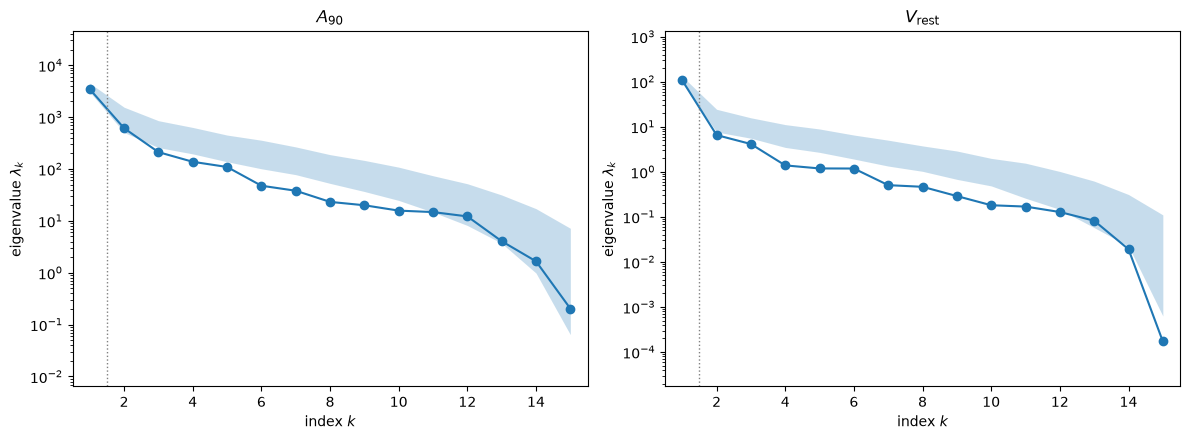

In [7]:
QA, QB = 'A90', 'Vrest'
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_eigenvalues(subs[QA], ax=axes[0])
ac.plotting.plot_eigenvalues(subs[QB], ax=axes[1])
axes[0].set_title(r'$A_{90}$')
axes[1].set_title(r'$V_{\rm rest}$')
fig.tight_layout()
plt.close(fig)
for q in (QA, QB):
    lam, b = subs[q].eigenvalues, subs[q].bootstrap_eigenvalues
    lo, hi = np.percentile(b[:, 0] / b[:, 1], [2.5, 97.5])
    lo2, hi2 = np.percentile(b[:, 1] / b[:, 2], [2.5, 97.5])
    print(f'{q}: eigenvalues {np.array2string(lam[:5], precision=4)} ...; lambda1/lambda2 = {lam[0] / lam[1]:.1f} '
          f'(bootstrap 95% [{lo:.1f}, {hi:.1f}]), lambda2/lambda3 = {lam[1] / lam[2]:.1f} ([{lo2:.1f}, {hi2:.1f}])')


def qphd_eigs(rows, f):
    """Eigenvalues of g g^T + H H / 3 from the quadratic fitted to the given rows (numpy, no v1 call)."""
    c = np.linalg.lstsq(Q[rows], f[rows], rcond=None)[0]
    g, H, k = c[1:16], np.zeros((15, 15)), 16
    for j in range(15):
        for i in range(j, 15):
            H[j, i] = H[i, j] = 2 * c[k] if i == j else c[k]
            k += 1
    return np.linalg.eigvalsh(np.outer(g, g) + H @ H / 3)[::-1]


rng_sub = np.random.default_rng(SEED)
subsets = [rng_sub.choice(M, 216, replace=False) for _ in range(300)]
for q in (QA, QB):
    lf = qphd_eigs(np.arange(M), F[q])
    rs = [(lambda l: l[0] / l[1])(qphd_eigs(s, F[q])) for s in subsets]
    print(f'{q}: lambda1/lambda2 over 300 subsamples of 216 distinct rows: 5-95 % '
          f'[{np.percentile(rs, 5):.1f}, {np.percentile(rs, 95):.1f}], median {np.median(rs):.1f} '
          f'(all rows, same formula: {lf[0] / lf[1]:.1f})')
fig

For $A_{90}$, $\lambda_1 = 3446$ is 5.6 times $\lambda_2 = 611$ (bootstrap 95 % interval of the ratio 2.6–6.6), and the following eigenvalues fall slowly (211, 138, 109): one leading direction, but not a sharp gap. For $V_{\rm rest}$ the ratio is 16.3, with a bootstrap interval of 4.4–14.2 that lies below the estimate itself: resampling with replacement repeats rows, which adds noise to the 136-coefficient fit and inflates the small eigenvalue $\lambda_2$. Subsamples of 216 distinct rows (without replacement) give a 5–95 % range of 9.0–17.2 for $V_{\rm rest}$ (median 12.4), which contains the estimate, and 3.7–6.8 for $A_{90}$. The gap is real; its size is uncertain by a factor of about 2.

#### Subspace errors

A90: bootstrap mean subspace distance, k = 1..4: [0.171 0.5   0.808 0.876]
Vrest: bootstrap mean subspace distance, k = 1..4: [0.133 0.725 0.791 0.943]


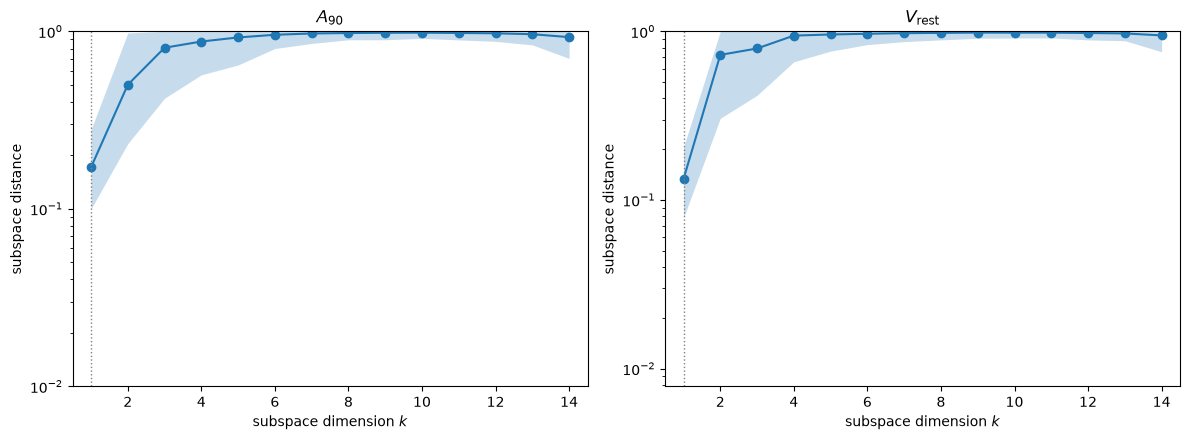

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_subspace_errors(subs[QA], ax=axes[0])
ac.plotting.plot_subspace_errors(subs[QB], ax=axes[1])
axes[0].set_title(r'$A_{90}$')
axes[1].set_title(r'$V_{\rm rest}$')
fig.tight_layout()
plt.close(fig)
for q in (QA, QB):
    print(f'{q}: bootstrap mean subspace distance, k = 1..4:',
          np.array2string(subs[q].bootstrap_distances.mean(axis=0)[:4], precision=3))
fig

The bootstrap mean subspace distance for $n = 1$ is 0.171 for $A_{90}$ and 0.133 for $V_{\rm rest}$, so $\mathbf w_1$ is determined to roughly 13–17 % by 288 rows; for $n = 2$ it is 0.50 and 0.725, so the second direction is not determined.

#### Eigenvectors

A90 w1: pNaK +0.62, pK1 -0.44, pCaL +0.06, pCap -0.02, pNa -0.00, pKr -0.29, pNaCa +0.15, pKs -0.01, pClCa -0.16, pNab -0.04, ptos -0.16, pClb -0.49, pCab -0.12, pKp -0.04, ptof -0.04
A90 w2: pNaK -0.66, pK1 -0.00, pCaL +0.22, pCap -0.10, pNa -0.02, pKr -0.38, pNaCa +0.07, pKs -0.04, pClCa -0.14, pNab -0.09, ptos -0.09, pClb -0.52, pCab +0.17, pKp +0.07, ptof +0.11
Vrest w1: pNaK -0.16, pK1 -0.87, pCaL -0.00, pCap -0.09, pNa +0.04, pKr -0.04, pNaCa -0.05, pKs -0.01, pClCa -0.00, pNab +0.03, ptos -0.02, pClb +0.38, pCab +0.21, pKp +0.02, ptof -0.09
Vrest w2: pNaK -0.04, pK1 +0.43, pCaL +0.00, pCap -0.05, pNa -0.13, pKr +0.02, pNaCa +0.01, pKs +0.09, pClCa -0.13, pNab +0.03, ptos +0.05, pClb +0.84, pCab +0.16, pKp +0.09, ptof -0.14


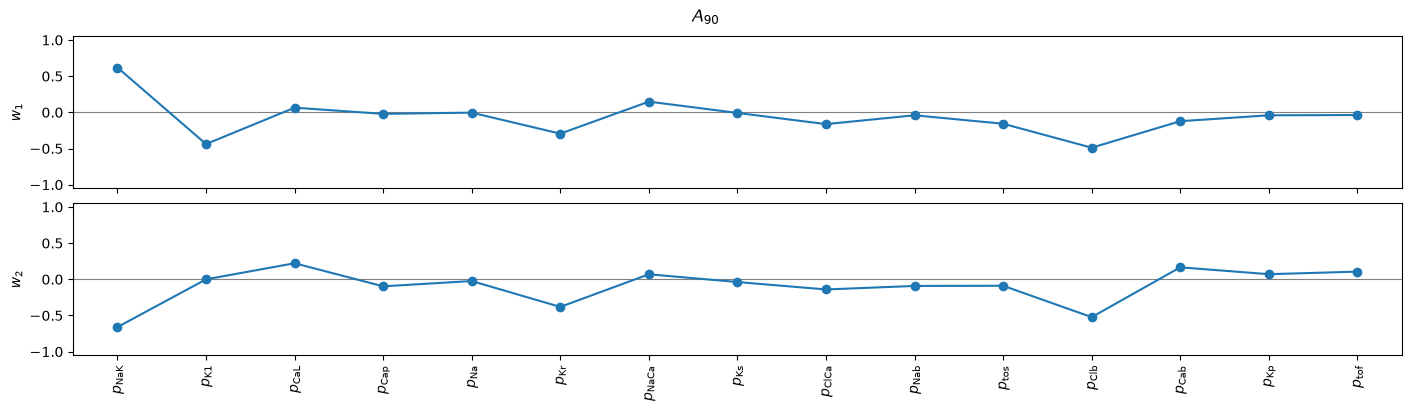

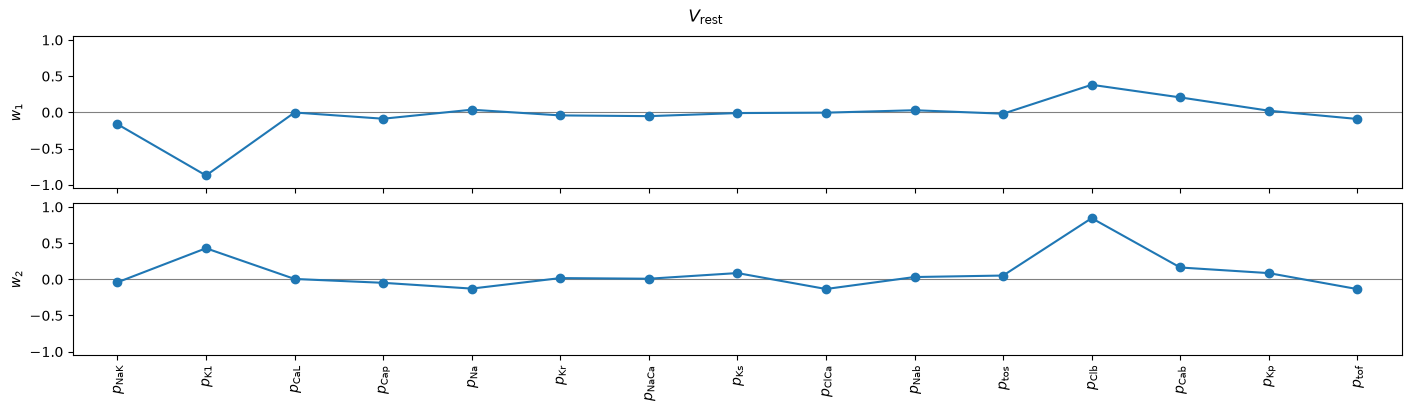

In [9]:
fig1, _ = ac.plotting.plot_eigenvectors(subs[QA], indices=[0, 1], labels=labels, figsize=(14, 4))
fig1.suptitle(r'$A_{90}$')
fig2, _ = ac.plotting.plot_eigenvectors(subs[QB], indices=[0, 1], labels=labels, figsize=(14, 4))
fig2.suptitle(r'$V_{\rm rest}$')
plt.close(fig1)
plt.close(fig2)
for q in (QA, QB):
    for c in (0, 1):
        print(f'{q} w{c + 1}: ' + ', '.join(f'{n} {v:+.2f}' for n, v in zip(NAMES, subs[q].W[:, c])))
display(fig1)
fig2

For $A_{90}$, $\mathbf w_1$ weighs $p_{\rm NaK}$ (+0.62), $p_{\rm Clb}$ (−0.49), $p_{\rm K1}$ (−0.44) and $p_{\rm Kr}$ (−0.29): the AP is longer with a stronger Na-K pump and shorter with stronger background Cl, inward rectifier and rapid delayed rectifier currents. The repolarizing K currents and $I_{\rm Clb}$ have the signs one expects. The positive sign of $p_{\rm NaK}$ is the opposite of the paper's one-at-a-time sweep (Fig 2(a), p. 12, where $A_{90}$ falls from about 300 ms near $p_{\rm NaK} = 0$ to about 245 ms at 0.5 and 205 ms at 1), but it is already there one at a time at beat 1000: varying $p_{\rm NaK}$ alone, with the other factors at 1, gives $A_{90}$ = 86.7 ms at $p_{\rm NaK} = 0.1$ and 204.7 ms at 1.0 (`check_accuracy.py --scipy`, check 2, which integrates the same model file with scipy instead of CVODES; at 0.5 the stimulus fails at beat 1000, a near-threshold effect). What changes is the beat: at beat 5 the same three runs give 308.5, 265.4 and 231.1 ms at $p_{\rm NaK}$ = 0.1, 0.5 and 1.0 (beat 20: 292.1, 255.2, 228.8 ms), the falling curve of Fig 2(a); at beat 100 they are about equal (208.5, 204.9, 207.9 ms); by beat 1000 a weak pump has loaded the cell with Na ($[{\rm Na}^+]_i$ 26.95 mM at $p_{\rm NaK} = 0.1$ against 9.68 mM at 1.0, from 8.8 mM in the initial state), and the AP is short. So Fig 2(a) is matched at small $p_{\rm NaK}$ only by the first 5–20 beats of this model file, not by beat 1000, although the paper states 1000-beat trains (p. 10); which train produced it is asked of the authors (`DATA.md`). In the box, $p_{\rm Na}$ and $p_{\rm Nab}$ are mostly above 1 (means about 5.5 and 5.0), which adds to the Na loading: a rerun of 14 design rows (`DATA.md`; an external run) found $[{\rm Na}^+]_i$ at beat 1000 between 12.0 and 25.8 mM. For $V_{\rm rest}$, $\mathbf w_1$ is mostly $p_{\rm K1}$ (−0.87) with $p_{\rm Clb}$ (+0.38) and $p_{\rm Cab}$ (+0.21): a stronger inward rectifier holds the resting potential near $E_{\rm K}$, background Cl and Ca currents depolarize it.

#### Sufficient summary plots

A90: range [31.94, 228.65] ms; corr(y1, f) = +0.886, corr(y2, f) = +0.007
Vrest: range [-86.25, -60.47] mV; corr(y1, f) = +0.859, corr(y2, f) = +0.157


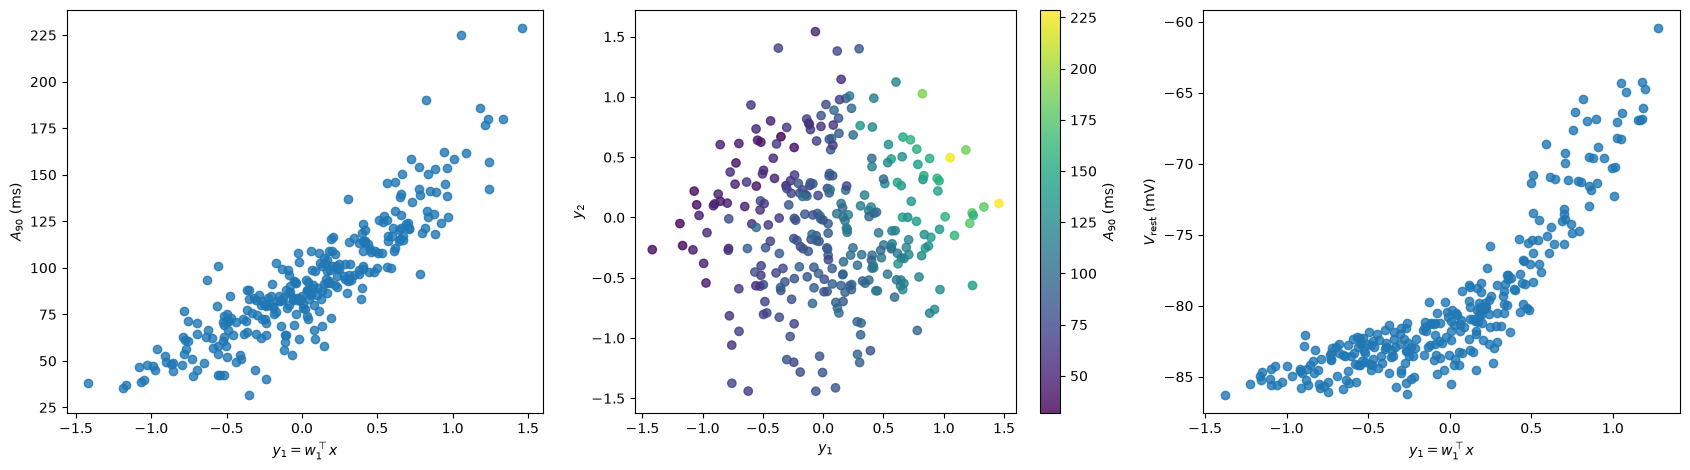

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ac.plotting.plot_sufficient_summary(subs[QA], X=X, f=F[QA], dims=1, qoi_label=r'$A_{90}$ (ms)', ax=axes[0])
sA2 = ac.with_dimension(subs[QA], 2)
ac.plotting.plot_sufficient_summary(sA2, X=X, f=F[QA], dims=2, qoi_label=r'$A_{90}$ (ms)', ax=axes[1])
ac.plotting.plot_sufficient_summary(subs[QB], X=X, f=F[QB], dims=1, qoi_label=r'$V_{\rm rest}$ (mV)', ax=axes[2])
fig.tight_layout()
plt.close(fig)
for q in (QA, QB):
    y = XN @ subs[q].W[:, :2]
    print(f'{q}: range [{F[q].min():.2f}, {F[q].max():.2f}] {UNITS[q]}; corr(y1, f) = {np.corrcoef(y[:, 0], F[q])[0, 1]:+.3f}, '
          f'corr(y2, f) = {np.corrcoef(y[:, 1], F[q])[0, 1]:+.3f}')
fig

$A_{90}$ (left; 31.9 to 228.7 ms) rises along $y_1$ with a correlation of 0.886 and wide scatter; in the two-dimensional plot (middle) the colour changes mainly along $y_1$ (correlation with $y_2$ 0.007; what $y_2$ adds is not linear, as the surrogates below show). $V_{\rm rest}$ (right; −86.25 to −60.47 mV) is a curved, monotone function of $y_1$ (correlation 0.859): flat near −86 mV for a strong inward rectifier and rising steeply as it weakens.

#### Surrogates on the active variables

Polynomials in the active variables, with leave-one-out $R^2$, for every biomarker: a cubic in $y_1$, a quadratic and a cubic in $(y_1, y_2)$; the last column repeats the quadratic in all 15 inputs. The plot is the cubic in $(y_1, y_2)$ for $A_{90}$.

QoI      cubic in y1  quadratic in (y1, y2)  cubic in (y1, y2)  quadratic in all 15
Vmax           0.759                  0.905              0.916                0.882
Vrest          0.886                  0.921              0.929                0.865
A90            0.819                  0.875              0.887                0.805
A30            0.865                  0.886              0.899                0.841
Vplt           0.668                  0.717              0.765                0.545
B              0.896                  0.922              0.935                0.889
Cai_ED         0.884                  0.719              0.881                0.369
Cai_PSV        0.956                  0.878              0.955                0.734


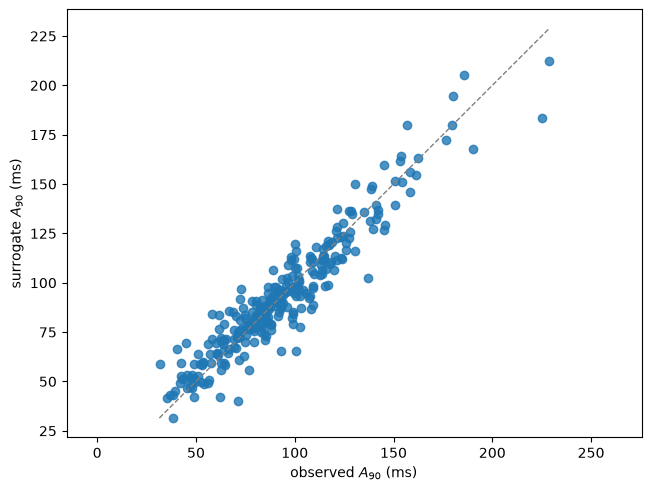

In [11]:
print(f"{'QoI':8s} {'cubic in y1':>11s} {'quadratic in (y1, y2)':>22s} {'cubic in (y1, y2)':>18s} {'quadratic in all 15':>20s}")
r2 = {}
for q in QOIS:
    s1 = ac.fit_surrogate(X=X, f=F[q], space=space, subspace=ac.with_dimension(subs[q], 1), kind='poly', degree=3)
    s2 = ac.fit_surrogate(X=X, f=F[q], space=space, subspace=ac.with_dimension(subs[q], 2), kind='poly', degree=2)
    s3 = ac.fit_surrogate(X=X, f=F[q], space=space, subspace=ac.with_dimension(subs[q], 2), kind='poly', degree=3)
    r2[q] = (s1.loo_r_squared, s2.loo_r_squared, s3.loo_r_squared)
    if q == QA:
        surA = s3
    print(f'{q:8s} ' + ' '.join(f'{v:{w}.3f}' if v is not None else f'{"n/a":>{w}s}'
                                 for v, w in zip(r2[q] + (loo[q],), (11, 22, 18, 20))))
fig, ax = ac.plotting.plot_surrogate_fit(surA, X=X, f=F[QA], qoi_label=r'$A_{90}$ (ms)')
plt.close(fig)
fig

Two active variables do as well as or better than the full quadratic in 15 inputs for every biomarker: for $A_{90}$ the cubic in $(y_1, y_2)$ has leave-one-out $R^2 = 0.887$ against 0.805 for the quadratic in all inputs (10 coefficients against 136), for $V_{\rm rest}$ 0.929 against 0.865, and for $B$ 0.935. One variable is enough for the Ca biomarkers (cubic in $y_1$: 0.884 for `Cai_ED`, 0.956 for `Cai_PSV`). $V_{\rm plt}$ is the hardest (0.765). The paper's comparable figure is a reduced model that keeps six factors and fixes nine: $R^2 = 0.93$ for $A_{90}$ (Table 7, p. 21).

### Comparison with the paper

The paper reports no active subspace; it reports Sobol' indices from $8192 \times 32$ Saltelli runs (Table 5, p. 14) and a grand total ranking (Eq 9). From 288 rows we cannot estimate Sobol' indices directly, but we can compute them exactly for the least-squares quadratic fitted above (the formula is in the cell), with bootstrap intervals over the rows. These indices are those of the quadratic, which explains 55–89 % of the variance, so they are a rough check of the ranking, not a replacement for the paper's numbers. We also rank the factors by their activity scores $\sum_{k \le 2}\lambda_k w_{ik}^2$, each biomarker scaled by $\lambda_1 + \lambda_2$ and summed over the six AP biomarkers.

In [12]:
def quad_sobol(f, rows=None):
    """First-order and total Sobol' indices of the least-squares quadratic in the 15 inputs.

    With x uniform on [-1, 1]^15 and q = c + sum g_j x_j + sum a_j x_j^2 + sum_{j<k} b_jk x_j x_k,
    the terms g_j x_j, a_j (x_j^2 - 1/3) and b_jk x_j x_k are orthogonal, with variances
    g_j^2/3, 4 a_j^2/45 and b_jk^2/9, so the indices are exact for the quadratic."""
    rows = np.arange(len(f)) if rows is None else rows
    c = np.linalg.lstsq(Q[rows], f[rows], rcond=None)[0]
    m = 15
    g, a, B = c[1:m + 1], np.zeros(m), np.zeros((m, m))
    k = m + 1
    for j in range(m):
        for i in range(j, m):
            if i == j:
                a[j] = c[k]
            else:
                B[j, i] = B[i, j] = c[k]
            k += 1
    V1 = g**2 / 3 + 4 * a**2 / 45
    V2 = B**2 / 9
    V = V1.sum() + np.triu(V2, 1).sum()
    return V1 / V, (V1 + V2.sum(axis=1)) / V


rng = np.random.default_rng(SEED)
boot_rows = [rng.integers(0, M, M) for _ in range(500)]
S1, ST, CI1, CIT = {}, {}, {}, {}
for q in QOIS[:6]:
    S1[q], ST[q] = quad_sobol(F[q])
    bs = np.array([np.concatenate(quad_sobol(F[q], r)) for r in boot_rows])
    CI1[q] = np.percentile(bs[:, :15], [2.5, 97.5], axis=0)
    CIT[q] = np.percentile(bs[:, 15:], [2.5, 97.5], axis=0)

# Table 5 of the paper (p. 14): the top three first-order and total indices, with their 95% CI
table5 = {
    'A30': ([('pClb', .33), ('pNaCa', .063), ('pClCa', .036)], [('pClb', .82), ('pKr', .49), ('pNaCa', .47)]),
    'A90': ([('pClb', .35), ('pKr', .14), ('pNaCa', .14)], [('pClb', .54), ('pKr', .34), ('pNaCa', .24)]),
    'B': ([('pClb', .45), ('pNaCa', .076), ('pCaL', .031)], [('pClb', .72), ('pKr', .26), ('pNaCa', .24)]),
    'Vplt': ([('pClb', .23), ('pK1', .17), ('pCaL', .15)], [('pClb', .41), ('pK1', .35), ('pKr', .26)]),
    'Vmax': ([('pCaL', .32), ('pClb', .25), ('ptos', .050)], [('pClb', .44), ('pCaL', .40), ('pK1', .14)]),
    'Vrest': ([('pK1', .23), ('pKr', .068), ('pClb', .041)], [('pClb', .55), ('pKr', .54), ('pK1', .47)]),
}
print('Sobol indices: paper Table 5 vs the quadratic fit to these data (bootstrap 95% interval)')
for q, (first, total) in table5.items():
    j1 = [NAMES.index(p) for p, _ in first]
    jT = [NAMES.index(p) for p, _ in total]
    print(f'{q:5s} S1: ' + '; '.join(f'{p} {v:.3g} vs {S1[q][j]:.3f} [{CI1[q][0, j]:.3f}, {CI1[q][1, j]:.3f}]'
                                    for (p, v), j in zip(first, j1)))
    print(f'      ST: ' + '; '.join(f'{p} {v:.3g} vs {ST[q][j]:.3f} [{CIT[q][0, j]:.3f}, {CIT[q][1, j]:.3f}]'
                                    for (p, v), j in zip(total, jT)))
    print(f'      top 3 here: S1 {", ".join(NAMES[j] for j in np.argsort(-S1[q])[:3])}; '
          f'ST {", ".join(NAMES[j] for j in np.argsort(-ST[q])[:3])}; sum S1 = {S1[q].sum():.2f}')

paper_rank = ['pClb', 'pKr', 'pK1', 'pCaL', 'pNaCa', 'pKs', 'pNaK', 'ptos', 'pClCa', 'pCab', 'ptof', 'pCap',
              'pNab', 'pNa', 'pKp']                          # Eq (9), p. 14
SG = sum(ST[q] for q in QOIS[:6])
rank_sg = [NAMES[j] for j in np.argsort(-SG)]
act = sum(ac.activity_scores(subs[q], n=2) / subs[q].eigenvalues[:2].sum() for q in QOIS[:6])
rank_act = [NAMES[j] for j in np.argsort(-act)]
print('\ngrand total ranking, paper Eq (9):     ', ' '.join(paper_rank))
print('grand total of the quadratic fit:       ', ' '.join(rank_sg))
print('summed activity scores (n = 2, scaled): ', ' '.join(rank_act))
for name, r in (('quadratic grand total', rank_sg), ('activity scores', rank_act)):
    print(f'{name}: top 6 shared with the paper: {len(set(r[:6]) & set(paper_rank[:6]))}; '
          f'Spearman rank correlation with Eq (9): '
          f'{np.corrcoef([paper_rank.index(n) for n in NAMES], [r.index(n) for n in NAMES])[0, 1]:.2f}')

Sobol indices: paper Table 5 vs the quadratic fit to these data (bootstrap 95% interval)
A30   S1: pClb 0.33 vs 0.171 [0.107, 0.198]; pNaCa 0.063 vs 0.021 [0.007, 0.037]; pClCa 0.036 vs 0.088 [0.050, 0.103]
      ST: pClb 0.82 vs 0.298 [0.224, 0.327]; pKr 0.49 vs 0.037 [0.025, 0.074]; pNaCa 0.47 vs 0.061 [0.042, 0.103]
      top 3 here: S1 pNaK, pClb, pClCa; ST pNaK, pClb, pClCa; sum S1 = 0.76
A90   S1: pClb 0.35 vs 0.164 [0.088, 0.181]; pKr 0.14 vs 0.057 [0.023, 0.072]; pNaCa 0.14 vs 0.031 [0.010, 0.049]
      ST: pClb 0.54 vs 0.237 [0.169, 0.269]; pKr 0.34 vs 0.104 [0.069, 0.139]; pNaCa 0.24 vs 0.037 [0.027, 0.076]
      top 3 here: S1 pNaK, pK1, pClb; ST pNaK, pClb, pK1; sum S1 = 0.82
B     S1: pClb 0.45 vs 0.232 [0.161, 0.250]; pNaCa 0.076 vs 0.017 [0.007, 0.029]; pCaL 0.031 vs 0.003 [0.000, 0.011]
      ST: pClb 0.72 vs 0.344 [0.275, 0.365]; pKr 0.26 vs 0.060 [0.041, 0.089]; pNaCa 0.24 vs 0.030 [0.022, 0.061]
      top 3 here: S1 pNaK, pClb, pClCa; ST pNaK, pClb, pClCa; sum S1 = 0

| quantity | paper | this notebook |
|---|---|---|
| response outside the normal 1:1 region in the box | not reported (box found one factor at a time) | 32 of 320 runs (16 no AP, 16 alternans or 2:1) |
| $A_{90}$ one at a time, $p_{\rm NaK}$ = 0.1, 0.5, 1.0 (others 1) | about 290, 245, 205 ms (read from Fig 2(a), p. 12), stated as beat 1000 | beat 5: 308.5, 265.4, 231.1 ms; beat 20: 292.1, 255.2, 228.8; beat 1000: 86.7, no AP, 204.7 (`check_accuracy.py --scipy`) |
| steady state after 1000 beats | changes < 2 % (Fig 1, one point: $p_{\rm NaK} = 0.5$, $p_{\rm NaCa} = 0.3$, others 1; $p_{\rm NaCa}$ is outside the box [0.6, 3], and $p_{\rm Na} = p_{\rm Nab} = 1$ while their box means are 5.5 and 5.0) | $A_{90}$: median change 3.2 % between beats 500 and 1000; 60 % of rows above 2 %; median 21 % for $p_{\rm NaK} < 0.3$ |
| full-model biomarkers over the box, median (5–95 %) | authors' repository, 2000 stored runs: $A_{90}$ 144.2 ms (87.5–307.3), $V_{\max}$ 21.0 mV, $V_{\rm plt}$ −5.3 mV | beat 1000: $A_{90}$ 88.6 ms (45.9–152.3), $V_{\max}$ 15.0 mV, $V_{\rm plt}$ −18.0 mV; beat 500: 95.7 ms, 16.2 mV, −18.4 mV |
| $A_{90}$: top first-order index | $p_{\rm Clb}$ 0.35 | $p_{\rm NaK}$; $p_{\rm Clb}$ 0.164 (0.088–0.181), third |
| $A_{90}$: top total index | $p_{\rm Clb}$ 0.54, $p_{\rm Kr}$ 0.34, $p_{\rm NaCa}$ 0.24 | $p_{\rm NaK}$, $p_{\rm Clb}$ 0.237, $p_{\rm K1}$; $p_{\rm Kr}$ 0.104, $p_{\rm NaCa}$ 0.037 |
| $V_{\rm rest}$: top first-order index | $p_{\rm K1}$ 0.23 | $p_{\rm K1}$ 0.587 (0.399–0.561) |
| $V_{\max}$: top first-order index | $p_{\rm CaL}$ 0.32 | $p_{\rm NaK}$; $p_{\rm CaL}$ 0.086 (0.056–0.105) |
| grand ranking, first six | $p_{\rm Clb}, p_{\rm Kr}, p_{\rm K1}, p_{\rm CaL}, p_{\rm NaCa}, p_{\rm Ks}$ | quadratic: $p_{\rm NaK}, p_{\rm Clb}, p_{\rm K1}, p_{\rm ClCa}, p_{\rm Cab}, p_{\rm tos}$; activity scores: $p_{\rm NaK}, p_{\rm Clb}, p_{\rm K1}, p_{\rm ClCa}, p_{\rm tos}, p_{\rm Kr}$ |
| rank correlation with Eq (9) | | 0.56 (quadratic), 0.65 (activity scores) |
| reduced model for $A_{90}$ | 6 factors, $R^2 = 0.93$ (Table 7) | 2 active variables, LOO $R^2 = 0.887$ |
| active subspace | not reported | $n = 1$ for every biomarker; $\lambda_1/\lambda_2$ = 5.6 ($A_{90}$), 16.3 ($V_{\rm rest}$) |
| $A_{90}$ at beat 500 | | $\mathbf w_1$ led by $p_{\rm Clb}$, $p_{\rm K1}$, $p_{\rm Kr}$ |
| $A_{90}$, sub-box $p_{\rm NaK} \ge 0.3$ (nonlinearity check) | | $\mathbf w_1$ led by $p_{\rm Clb}$, $p_{\rm K1}$, $p_{\rm Kr}$; $\lambda_1/\lambda_2 = 9.0$ |

Two things agree with the paper: $p_{\rm Clb}$ and $p_{\rm K1}$ are among the three most important factors overall, and $p_{\rm K1}$ leads $V_{\rm rest}$. The main disagreement is $p_{\rm NaK}$, first here for five of the six AP biomarkers and seventh in Eq (9), and the small weights of $p_{\rm Kr}$ and $p_{\rm NaCa}$. It comes with a mismatch in the model runs themselves, which may be its origin: the authors' 2000 stored full-model runs over the same box have longer APs and higher peaks and plateaus than ours. We do not know the cause. On paper the protocol is the same: the paper (p. 10) and the authors' `output_for_AP_features.py` use the same model file (byte-identical), the same initial state, stimulus and 1000 beats. But the paper's own one-at-a-time Fig 2(a) does not match beat 1000 of this file: varying $p_{\rm NaK}$ alone, its falling curve (about 300 ms at small $p_{\rm NaK}$) appears only in the first 5–20 beats, and at beat 1000 a weak pump gives the shortest APs (86.7 ms at $p_{\rm NaK} = 0.1$; table above). So the authors' cells look less Na-loaded than a 1000-beat train of this file makes them. The same points that way: at beat 500 our $A_{90}$ and $V_{\max}$ orderings are close to Table 5, and in the 14-row rerun (`DATA.md`) the biomarkers of beats 5–100 of the same train move the medians of $V_{\max}$, $V_{\rm plt}$ and $V_{\rm rest}$ close to the stored ones, though $A_{90}$ and $A_{30}$ stay shorter. It is not the biomarker definitions, which differ only in detail (`DATA.md`). Fewer effective beats, a different model file (the authors' `fig010.py` loads `shannonRado.mmt` and pre-paces 99 beats) or a different Myokit version could do this; the repository does not say which produced the stored runs or the Saltelli runs, and the question is open with the authors. We keep the 1000-beat biomarkers, the paper's stated protocol. The two other differences do not change the headline: dropping the 32 abnormal runs thins the weak-pump part of the design, but with them kept $p_{\rm NaK}$ still leads $A_{90}$ and $V_{\max}$ (check (d)); and our Sobol' indices are those of a quadratic that misses 11–45 % of the variance. At beat 1000, $p_{\rm Kr}$ and $p_{\rm NaCa}$ are weaker here than in the paper; at beat 500, $p_{\rm Kr}$ is third for $A_{90}$, but $p_{\rm NaCa}$ is not in the top three of any AP biomarker. Note also that the bootstrap intervals of the quadratic's indices can exclude the full-data value ($p_{\rm K1}$ for $V_{\rm rest}$: 0.587, interval 0.399–0.561), a sign of bias in bootstrapping a 136-coefficient fit on 288 rows. The paper's own Fig 2(a) shows a one-at-a-time effect of about 100 ms of $p_{\rm NaK}$ on $A_{90}$, larger than its rank suggests.

### References

[1] Z. Yang, H. Gao, G. L. Smith, R. D. Simitev, Dominant ionic currents in rabbit ventricular action potential dynamics, *PLOS ONE* 20(7):e0328261, 2025. [doi:10.1371/journal.pone.0328261](https://doi.org/10.1371/journal.pone.0328261). Code: <https://github.com/ZhechaoYanggla/Sobol_paper>.

[2] T. R. Shannon, F. Wang, J. Puglisi, C. Weber, D. M. Bers, A mathematical treatment of integrated Ca dynamics within the ventricular myocyte, *Biophysical Journal* 87(5):3351–3371, 2004. [doi:10.1529/biophysj.104.047449](https://doi.org/10.1529/biophysj.104.047449)

[3] P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

[4] M. Clerx, P. Collins, E. de Lange, P. G. A. Volders, Myokit: a simple interface to cardiac cellular electrophysiology, *Progress in Biophysics and Molecular Biology* 120(1–3):100–114, 2016. [doi:10.1016/j.pbiomolbio.2015.12.008](https://doi.org/10.1016/j.pbiomolbio.2015.12.008)

[5] M. J. W. Jansen, Analysis of variance designs for model output, *Computer Physics Communications* 117(1–2):35–43, 1999. [doi:10.1016/S0010-4655(98)00154-4](https://doi.org/10.1016/S0010-4655(98)00154-4)

### Acknowledgments

The paper's work was supported by the UK Engineering and Physical Sciences Research Council (grants EP/S030875/1 and EP/T017899/1).

In [13]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 24 s
